# Experiment 6: A Simple Neural Network
**CSAI4014 AISR Laboratory** | Name: `<Suhani Baderia>` | SAP ID: `<500119327>` | Batch: `<4>`

A 2-layer neural network written from scratch in NumPy (no deep-learning framework) learns
**XOR**, a problem no single-layer perceptron can solve because it is not linearly separable.
We train with full-batch gradient descent and back-propagation, compare learning rates, and plot
the decision boundary.

Forward pass: $h = \sigma(XW_1 + b_1)$, $\hat y = \sigma(hW_2 + b_2)$, with $\sigma(z)=1/(1+e^{-z})$.
Loss: mean squared error $L = \frac{1}{2m}\sum (\hat y - y)^2$.
Back-propagation: $\delta_2 = (\hat y - y)\,\hat y(1-\hat y)/m$, $\delta_1 = (\delta_2 W_2^T)\,h(1-h)$,
$W \leftarrow W - \eta\,\partial L/\partial W$.

In [1]:
import os
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

os.makedirs("figs", exist_ok=True)
os.makedirs("tables", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})
print("Python:", platform.python_version(), "| NumPy:", np.__version__, "| Matplotlib:", matplotlib.__version__)
print("OS    :", platform.platform())

Python: 3.13.9 | NumPy: 2.3.5 | Matplotlib: 3.10.6
OS    : Windows-11-10.0.26300-SP0


## Data and set-up

In [2]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

N_IN, N_HIDDEN, N_OUT = 2, 3, 1
EPOCHS = 20000
LEARNING_RATES = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 100.0]
INIT_SEED = 9327           
LOSS_TOL = 1e-3           

setup = [
    ["Task", "XOR (4 samples)"], ["Architecture", f"{N_IN}-{N_HIDDEN}-{N_OUT}, fully connected"],
    ["Activation", "sigmoid (hidden and output)"], ["Loss", "mean squared error (1/2m)"],
    ["Optimiser", "full-batch gradient descent"], ["Epochs", EPOCHS],
    ["Weight init", f"uniform(-1, 1), seed {INIT_SEED}; biases 0"],
    ["Learning rates tried", LEARNING_RATES], ["Convergence criterion", f"loss < {LOSS_TOL} and 4/4 correct"],
]
for k, v in setup:
    print(f"{k:<24}{v}")
np.savetxt("tables/T6_1_network_setup.csv", np.array(setup, dtype=object), fmt="%s", delimiter=";",
           header="Item;Value", comments="")

Task                    XOR (4 samples)
Architecture            2-3-1, fully connected
Activation              sigmoid (hidden and output)
Loss                    mean squared error (1/2m)
Optimiser               full-batch gradient descent
Epochs                  20000
Weight init             uniform(-1, 1), seed 9327; biases 0
Learning rates tried    [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 100.0]
Convergence criterion   loss < 0.001 and 4/4 correct


## The network

In [3]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def init_params(seed):
    rng = np.random.default_rng(seed)
    return {"W1": rng.uniform(-1, 1, (N_IN, N_HIDDEN)), "b1": np.zeros((1, N_HIDDEN)),
            "W2": rng.uniform(-1, 1, (N_HIDDEN, N_OUT)), "b2": np.zeros((1, N_OUT))}

def forward(p, X):
    h = sigmoid(X @ p["W1"] + p["b1"])
    out = sigmoid(h @ p["W2"] + p["b2"])
    return h, out

def train(lr, seed=INIT_SEED, epochs=EPOCHS):
    p = init_params(seed)
    m = len(X)
    losses = np.empty(epochs)
    for e in range(epochs):
        h, out = forward(p, X)
        losses[e] = 0.5 * np.mean((out - y) ** 2)
        d2 = (out - y) * out * (1 - out) / m           # dL/dz2
        d1 = (d2 @ p["W2"].T) * h * (1 - h)            # dL/dz1
        p["W2"] -= lr * h.T @ d2;  p["b2"] -= lr * d2.sum(0, keepdims=True)
        p["W1"] -= lr * X.T @ d1;  p["b1"] -= lr * d1.sum(0, keepdims=True)
    return p, losses

### Gradient check (verifies back-propagation against finite differences)

In [4]:
def loss_of(p):
    return 0.5 * np.mean((forward(p, X)[1] - y) ** 2)

p = init_params(0)
h, out = forward(p, X)
d2 = (out - y) * out * (1 - out) / len(X)
analytic = h.T @ d2
numeric = np.zeros_like(p["W2"])
for i in range(numeric.shape[0]):
    p["W2"][i, 0] += 1e-6; lp = loss_of(p); p["W2"][i, 0] -= 2e-6; lm = loss_of(p); p["W2"][i, 0] += 1e-6
    numeric[i, 0] = (lp - lm) / 2e-6
print("max |analytic - numeric| for dL/dW2:", float(np.abs(analytic - numeric).max()))

max |analytic - numeric| for dL/dW2: 1.4259994227105999e-11


## Effect of learning rate

In [5]:
runs = {}
rows = []
print(f"{'lr':>6}{'Final loss':>13}{'Epochs to tol':>15}{'Correct':>9}{'Converged':>11}")
for lr in LEARNING_RATES:
    p, losses = train(lr)
    pred = forward(p, X)[1]
    correct = int(((pred > 0.5) == (y > 0.5)).sum())
    hit = np.flatnonzero(losses < LOSS_TOL)
    ep_tol = int(hit[0]) + 1 if hit.size else None
    conv = losses[-1] < LOSS_TOL and correct == 4
    runs[lr] = (p, losses, conv)
    rows.append([lr, losses[-1], ep_tol if ep_tol else f">{EPOCHS}", f"{correct}/4", "Yes" if conv else "No"])
    print(f"{lr:6g}{losses[-1]:13.2e}{str(rows[-1][2]):>15}{rows[-1][3]:>9}{rows[-1][4]:>11}")
np.savetxt("tables/T6_2_effect_of_learning_rate.csv", np.array(rows, dtype=object), fmt="%s", delimiter=",",
           header="Learning rate,Final loss,Epochs to reach loss<tol,Correct outputs,Converged", comments="")

    lr   Final loss  Epochs to tol  Correct  Converged
  0.01     1.25e-01         >20000      2/4         No
   0.1     8.00e-03         >20000      4/4         No
   0.5     3.11e-04           9246      4/4        Yes
     1     1.29e-04           4624      4/4        Yes
     2     5.74e-05           2313      4/4        Yes
     5     2.07e-05            926      4/4        Yes
   100     9.83e-07           5876      4/4        Yes


### Robustness across initialisations (for the Discussion)
A 2-3-1 sigmoid network can sometimes get stuck in a local minimum. We repeat the best two
learning rates from 20 random initialisations.

In [6]:
for lr in (1.0, 2.0):
    ok = sum(((forward(pp, X)[1] > 0.5) == (y > 0.5)).all() and l[-1] < LOSS_TOL
             for pp, l in (train(lr, seed=s) for s in range(20)))
    print(f"lr = {lr}: converged in {ok}/20 random initialisations")

lr = 1.0: converged in 20/20 random initialisations
lr = 2.0: converged in 20/20 random initialisations


## Figure 6.1 – loss curves

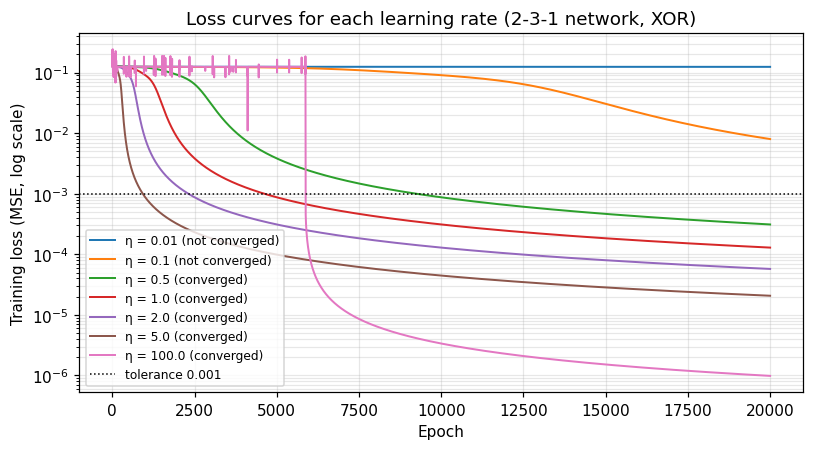

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for lr in LEARNING_RATES:
    _, losses, conv = runs[lr]
    ax.semilogy(np.arange(1, EPOCHS + 1), losses, lw=1.3,
                label=f"η = {lr} ({'converged' if conv else 'not converged'})")
ax.axhline(LOSS_TOL, color="k", ls=":", lw=1, label=f"tolerance {LOSS_TOL}")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training loss (MSE, log scale)")
ax.set_title("Loss curves for each learning rate (2-3-1 network, XOR)")
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("figs/fig6_1_loss_curves.png")
plt.show()

## Best run: predicted outputs and decision boundary

In [8]:
best_lr = min((lr for lr in LEARNING_RATES if runs[lr][2]), key=lambda lr: runs[lr][1][-1])
p_best = runs[best_lr][0]
h_best, pred = forward(p_best, X)
pred_rows = [[int(a), int(b), int(t), float(o), int(o > 0.5), "✓" if (o > 0.5) == t else "✗"]
             for (a, b), t, o in zip(X, y[:, 0], pred[:, 0])]
print(f"Best run: learning rate {best_lr}")
print(f"{'x1':>3}{'x2':>4}{'target':>8}{'output':>10}{'class':>7}{'ok':>4}")
for r in pred_rows:
    print(f"{r[0]:3d}{r[1]:4d}{r[2]:8d}{r[3]:10.4f}{r[4]:7d}{r[5]:>4}")
np.savetxt("tables/T6_3_predicted_outputs_best_run.csv", np.array(pred_rows, dtype=object), fmt="%s",
           delimiter=",", header="x1,x2,Target,Network output,Predicted class,Correct", comments="", encoding="utf-8")
print("\nTrained weights:\nW1 =\n", np.round(p_best["W1"], 3), "\nb1 =", np.round(p_best["b1"], 3),
      "\nW2 =", np.round(p_best["W2"].ravel(), 3), "\nb2 =", np.round(p_best["b2"], 3))

Best run: learning rate 100.0
 x1  x2  target    output  class  ok
  0   0       0    0.0003      0   ✓
  0   1       1    0.9987      1   ✓
  1   0       1    0.9987      1   ✓
  1   1       0    0.0021      0   ✓

Trained weights:
W1 =
 [[ -3.266 -11.14   -6.706]
 [ -3.24  -11.122  -6.705]] 
b1 = [[-2.906  2.972  9.67 ]] 
W2 = [ -0.375 -16.225  13.821] 
b2 = [[-6.466]]


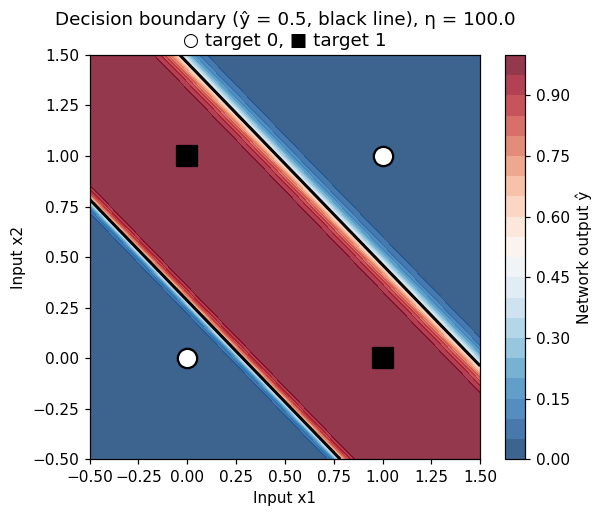

In [9]:
g = np.linspace(-0.5, 1.5, 300)
GX, GY = np.meshgrid(g, g)
Z = forward(p_best, np.c_[GX.ravel(), GY.ravel()])[1].reshape(GX.shape)
fig, ax = plt.subplots(figsize=(5.6, 4.8))
cf = ax.contourf(GX, GY, Z, levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.8)
ax.contour(GX, GY, Z, levels=[0.5], colors="k", linewidths=2)
fig.colorbar(cf, ax=ax, label="Network output ŷ")
for (a, b), t in zip(X, y[:, 0]):
    ax.scatter(a, b, s=160, marker="o" if t == 0 else "s", c="white" if t == 0 else "black",
               edgecolors="k", linewidths=1.5, zorder=3)
ax.set_xlabel("Input x1"); ax.set_ylabel("Input x2")
ax.set_title(f"Decision boundary (ŷ = 0.5, black line), η = {best_lr}\n○ target 0, ■ target 1")
fig.tight_layout()
fig.savefig("figs/fig6_2_decision_boundary.png")
plt.show()